# P2.10 — Big municipalities and their surroundings

**Question:** RQ4.3 (are prices rising faster in major urban centres than in the municipalities around them?). `p2_01` found
no outlier in the *change* in price-to-income against neighbours; here the question is asked directly on price growth.

A centre is a municipality with at least 100,000 residents in 2021 (a size rule: it takes the two metropolitan cores and
also their large suburbs). Distance is the number of border steps to the nearest centre. The first comparison is by
distance from a centre; the second is only the two cores, Lisboa and Porto, against the rest of their metropolitan areas.
Changes are 2016 to 2024 (the year the income data end), in real terms.

In [1]:
import pandas as pd

from pthousing.analysis import centres, descriptive, spatial
from pthousing.data import build_panel, harmonize, interim
from pthousing.viz import charts, style

style.apply_style()
panel = build_panel.read("panel_municipality_year")
geo = interim.read("caop_municipalities")
cw = harmonize.read_crosswalk().set_index("muni_code")
names = geo.set_index("muni_code")["muni_name"]
w = spatial.build_weights(geo, "queen")

population = panel.query("year == 2021").set_index("muni_code")["population_n"]
big = centres.find_centres(population)
steps = centres.steps_from_centre(w, big)
print(f"{len(big)} centres: {', '.join(names[c] for c in big)}")
print(steps.value_counts(dropna=False).sort_index().to_string())

25 centres: Lisboa, Sintra, Vila Nova de Gaia, Porto, Cascais, Loures, Braga, Almada, Amadora, Oeiras, Matosinhos, Seixal, Gondomar, Odivelas, Guimarães, Coimbra, Vila Franca de Xira, Santa Maria da Feira, Maia, Vila Nova de Famalicão, Leiria, Setúbal, Barcelos, Funchal, Viseu
steps_from_centre
0.0    25
1.0    59
2.0    71
3.0    54
4.0    34
5.0    29
6.0    11
7.0     5
NaN    20


## Step 1 — Price growth by distance from a centre

In [2]:
outcomes = {
    "price": descriptive.change(panel, "price_sqm_eur_real", 2016, 2024, "pct"),
    "income": descriptive.change(panel, "income_median_eur_real", 2016, 2024, "pct"),
    "pti": descriptive.change(panel, "pti_years", 2016, 2024, "pct"),
}
grad = centres.gradient(outcomes, steps)
style.save_table(grad.round(1).reset_index(), "p2", "centre_gradient")
grad["median"].unstack("outcome").round(1).join(
    grad.xs("price", level="outcome")["municipalities_n"].rename("n")
)

,price,income,pti,n
steps,,,,
0.0,107.9,18.0,73.3,25
1.0,63.2,29.8,26.0,58
2.0,44.5,30.1,13.7,71
3.0,42.9,30.9,13.3,52
4.0,43.8,28.2,14.1,78


## Step 2 — The same, with region effects
The gradient could be regional (the big centres are on the coast near Lisboa and Porto). With NUTS 3 fixed effects the contrast
is between a centre and the municipalities near it in the same region; it uses only regions with a centre.

In [3]:
region = cw["nuts3_name_2024"]
within = centres.gradient_within_regions(outcomes["price"], steps, region)
style.save_table(within.round(3).reset_index(), "p2", "centre_gradient_within_regions")
within_pti = centres.gradient_within_regions(outcomes["pti"], steps, region)
style.save_table(within_pti.round(3).reset_index(), "p2", "centre_gradient_within_regions_pti")
print("price:\n", within.round(2).to_string(), "\npti:\n", within_pti.round(2).to_string())

price:
        diff_log_points  ci_low  ci_high  p_value  municipalities_n  regions_with_centre_n
steps                                                                                    
1                -9.22  -14.96    -3.48      0.0              58.0                      9
2               -18.99  -29.63    -8.35      0.0              71.0                      9
3               -18.64  -30.30    -6.99      0.0             130.0                      9 
pti:
        diff_log_points  ci_low  ci_high  p_value  municipalities_n  regions_with_centre_n
steps                                                                                    
1               -14.42  -20.15    -8.69      0.0              58.0                      9
2               -24.94  -36.40   -13.48      0.0              70.0                      9
3               -23.66  -36.44   -10.89      0.0             126.0                      9


## Step 3 — The two cores against their metropolitan areas
Lisboa and Porto against the other municipalities of the metropolitan area (Grande Lisboa and Península de Setúbal; Área
Metropolitana do Porto), 2016 to 2024.

area        core rest_median rest_n  \
outcome                                                    
price   1106  Lisbon area     75.4083  111.762465     17   
        1312   Porto area  124.163669   84.352253     16   
income  1106  Lisbon area   15.780502   13.303597     17   
        1312   Porto area    10.93951   27.844256     16   
pti     1106  Lisbon area   52.781152   91.803332     17   
        1312   Porto area  103.541906   44.301284     16   

             share_of_rest_above_core_pct  
outcome                                    
price   1106                        100.0  
        1312                         12.5  
income  1106                    35.294118  
        1312                        100.0  
pti     1106                        100.0  
        1312                          0.0

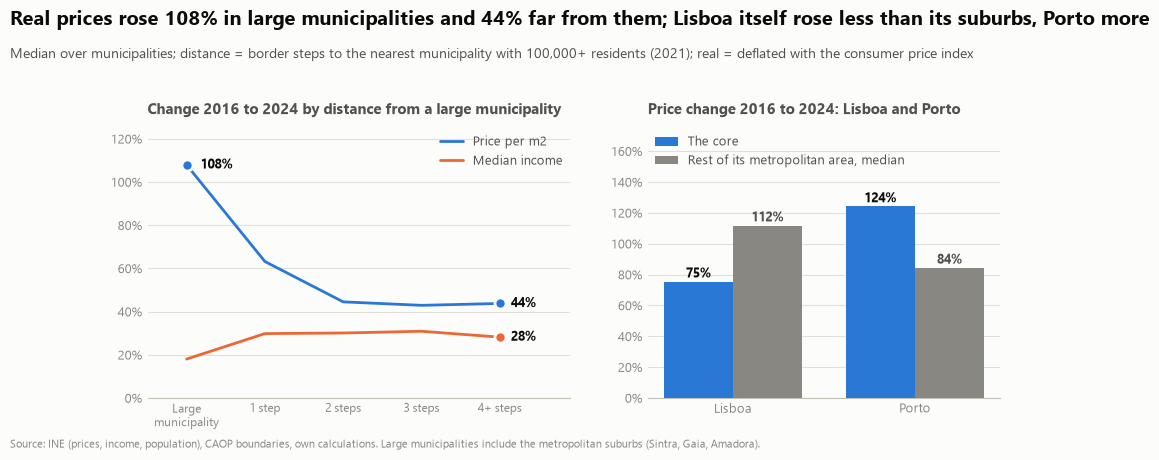

In [4]:
metro = region.map(
    {
        "Grande Lisboa": "Lisbon area",
        "Península de Setúbal": "Lisbon area",
        "Área Metropolitana do Porto": "Porto area",
    }
)
cores = [c for c, n in names.items() if n in ("Lisboa", "Porto")]
core_tbl = pd.concat(
    {k: centres.core_vs_rest(v, cores, metro) for k, v in outcomes.items()}, names=["outcome"]
)
style.save_table(core_tbl.reset_index(), "p2", "core_vs_metro")
fig = charts.centres_and_surroundings(grad, core_tbl, names)
style.save_fig(fig, "p2", "centres_and_surroundings")
core_tbl

## Key numbers

In [5]:
g = grad.xs("price", level="outcome")
print("price change by steps:", g["median"].round(0).to_dict(), g["municipalities_n"].to_dict())
print("pti change by steps:", grad.xs("pti", level="outcome")["median"].round(0).to_dict())
print("income change by steps:", grad.xs("income", level="outcome")["median"].round(0).to_dict())
for name, tbl in (("price", within), ("pti", within_pti)):
    print(
        name,
        {
            int(k): f"{r.diff_log_points:+.0f} [{r.ci_low:+.0f}, {r.ci_high:+.0f}]"
            for k, r in tbl.iterrows()
        },
        f"{int(tbl['regions_with_centre_n'].iloc[0])} regions with a centre",
    )

price change by steps: {0.0: 108.0, 1.0: 63.0, 2.0: 45.0, 3.0: 43.0, 4.0: 44.0} {0.0: 25, 1.0: 58, 2.0: 71, 3.0: 52, 4.0: 78}
pti change by steps: {0.0: 73.0, 1.0: 26.0, 2.0: 14.0, 3.0: 13.0, 4.0: 14.0}
income change by steps: {0.0: 18.0, 1.0: 30.0, 2.0: 30.0, 3.0: 31.0, 4.0: 28.0}
price {1: '-9 [-15, -3]', 2: '-19 [-30, -8]', 3: '-19 [-30, -7]'} 9 regions with a centre
pti {1: '-14 [-20, -9]', 2: '-25 [-36, -13]', 3: '-24 [-36, -11]'} 9 regions with a centre
